# Ellipsometry

An **ellipsometer** reflects polarized light from a sample under an
oblique angle and measures how the polarization changes: the ratio of
the reflection coefficients for p and s polarized light,

$$
\rho = \frac{r_p}{r_s} = \tan\Psi\, e^{i\Delta}.
$$

Because it measures a ratio, the intensity of the lamp and the
transmission of the optics drop out, and $\Delta$ is a phase difference
that responds to a tenth of a nanometre of oxide. Spectroscopic
ellipsometers measure $\Psi$ and $\Delta$ from the UV to the infrared
and at several angles; every thin film process in a semiconductor fab is
monitored with them. Ellipsometry is indirect: thicknesses and optical
constants come from fitting a model of the sample to the data, and much
of the art lies in the model.

This notebook uses the `ellipsometry` module, which computes $r_p$ and
$r_s$ with the characteristic matrices of `thin_films` (notebook 10,
interfaces and thin films):

1. $\Psi$ and $\Delta$ of bare substrates against the angle of incidence,
2. films: the sensitivity to a native oxide and the $\Psi$-$\Delta$
   trajectories, the pseudo-dielectric function,
3. instruments: rotating analyzer against rotating compensator,
4. dispersion models: Cauchy, Tauc-Lorentz, effective media,
5. spectroscopic model fits: a thermal oxide, the correlation of
   thickness and index of very thin films, an amorphous silicon film
   with surface roughness,
6. depolarization by a thick film and a finite bandwidth.

**Conventions.** Ellipsometry uses the "Nebraska conventions" (Muller
1969): $r_p$ with the reference directions of Born & Wolf ($r_p = -r_s$
at normal incidence) and the time dependence $e^{+i\omega t}$. pyoptics
uses $e^{-i\omega t}$ and tangential fields in `thin_films`, so the module
converts with $\rho = \overline{(-r_{p,\mathrm{tan}}/r_s)}$ and reports
$\Psi$ and $\Delta$ as in the literature and in instrument software: bare
silicon has $\Delta$ just below 180°, and $\Delta \in [0°, 360°)$. Angles
are in degrees, lengths in µm.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import ellipsometry as el
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

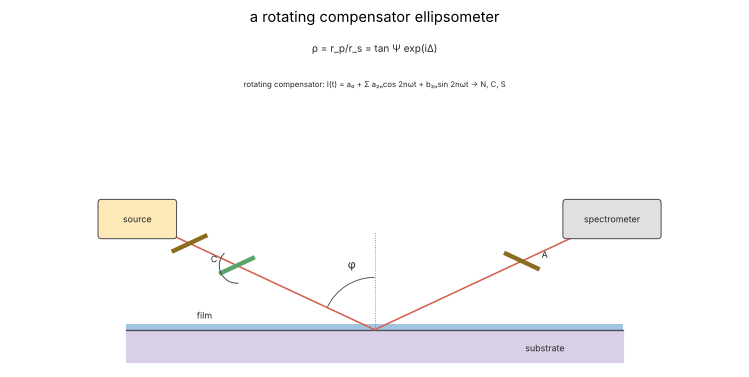

In [2]:
fig, ax = plt.subplots(figsize=(11, 4.6), layout="constrained")
sketch.metrology_layout(ax, "ellipsometer", title="a rotating compensator ellipsometer")
plt.show()

## 1. Bare substrates

For a transparent substrate $r_p$ vanishes at the Brewster angle: $\Psi$
drops to zero and $\Delta$ jumps from 180° to 0°. An absorbing substrate
has no zero, but a minimum of $\Psi$ at the **principal** (or
pseudo-Brewster) angle, where $\Delta$ passes 90° steeply. There $\Psi$
and $\Delta$ react most strongly to anything on the surface, which is
why ellipsometers work at 65° to 75° on silicon. The **pseudo-dielectric
function** inverts the measurement as if the sample were a bare
substrate,

$$
\langle\varepsilon\rangle = \sin^2\phi\left[1 + \tan^2\phi
  \left(\frac{1-\rho}{1+\rho}\right)^2\right],
$$

exact for a bare substrate (`el.pseudo_dielectric()`); with films on top
it is a convenient view of the raw data.

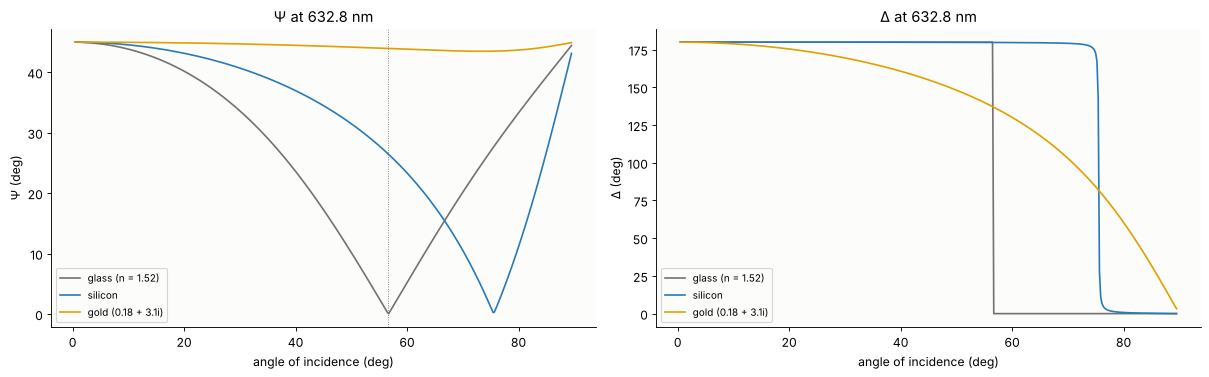

silicon: principal angle 75.4 deg (Psi = 0.25 deg, Delta = 142.5 deg), Brewster angle of glass 56.7 deg


In [3]:
ang = np.linspace(0.5, 89.5, 400)
subs = {"glass (n = 1.52)": (1.52, GREY), "silicon": (el.silicon_index(0.6328), BLUE),
        "gold (0.18 + 3.1i)": (0.18 + 3.1j, ORANGE)}
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
for name, (n, c) in subs.items():
    psi, delta = el.psi_delta(0.6328, ang, [], n)
    axs[0].plot(ang, psi, color=c, label=name)
    axs[1].plot(ang, delta, color=c, label=name)
axs[0].axvline(el.brewster_angle(1.52), color=GREY, ls=":", lw=0.8)
axs[0].set_ylabel("Ψ (deg)")
axs[1].set_ylabel("Δ (deg)")
for ax in axs:
    ax.set_xlabel("angle of incidence (deg)")
    ax.legend(fontsize=9)
axs[0].set_title("Ψ at 632.8 nm")
axs[1].set_title("Δ at 632.8 nm")
plt.show()
psi_si, delta_si = el.psi_delta(0.6328, ang, [], el.silicon_index)
i = np.argmin(psi_si)
print("silicon: principal angle {:.1f} deg (Psi = {:.2f} deg, Delta = {:.1f} deg), "
      "Brewster angle of glass {:.1f} deg".format(ang[i], psi_si[i], delta_si[i],
                                                 el.brewster_angle(1.52)))

## 2. Films

A film adds the phase $2k_0 d\sqrt{n^2 - \sin^2\phi}$ between the waves
reflected at its top and bottom, and $\Psi$ and $\Delta$ trace a closed
loop when the thickness grows by one period
$\lambda/(2\sqrt{n^2 - \sin^2\phi})$ (`el.film_period()`), 284 nm for
SiO₂ at 70° and 632.8 nm. Thin films sit near the bare substrate point,
where $\Delta$ changes fastest: the first nanometre of native oxide
lowers $\Delta$ by about 3°, and instruments resolve a few hundredths of
a degree. That is the sub-ångström sensitivity of ellipsometry.

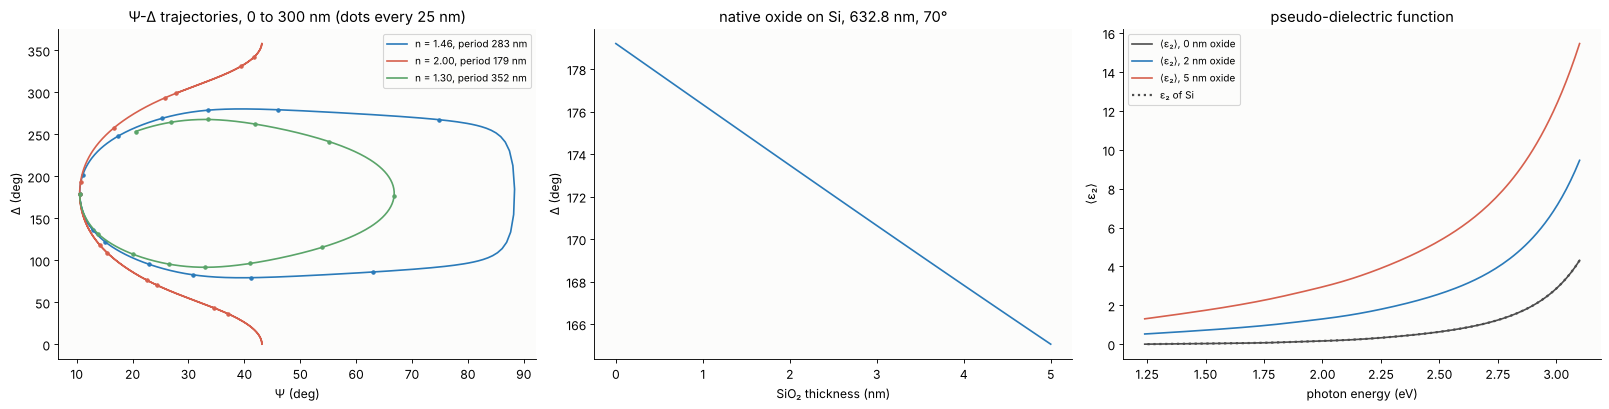

d Delta/d thickness for the first nm of oxide: -2.87 deg/nm


In [4]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5), layout="constrained")
d = np.linspace(0, 0.3, 601)
for n, c in ((1.46, BLUE), (2.0, RED), (1.30, GREEN)):
    P, D = [], []
    for dd in d:
        p, q = el.psi_delta(0.6328, 70.0, [(n, dd)], el.silicon_index)
        P.append(p)
        D.append(q)
    P, D = np.array(P), np.array(D)
    D_plot = np.where(np.abs(np.diff(D, prepend=D[0])) > 180, np.nan, D)   # break at 0/360
    axs[0].plot(P, D_plot, color=c, label="n = {:.2f}, period {:.0f} nm".format(
        n, el.film_period(0.6328, n, 70.0)*1e3))
    marks = np.arange(0, len(d), 50)
    axs[0].plot(np.array(P)[marks], np.array(D)[marks], "o", color=c, ms=3)
axs[0].set_xlabel("Ψ (deg)")
axs[0].set_ylabel("Δ (deg)")
axs[0].set_title("Ψ-Δ trajectories, 0 to 300 nm (dots every 25 nm)")
axs[0].legend(fontsize=9)
dd = np.linspace(0, 0.005, 51)
D0 = np.array([el.psi_delta(0.6328, 70.0, [(el.sio2_index, x)] if x > 0 else [],
                            el.silicon_index)[1] for x in dd])
axs[1].plot(dd*1e3, D0, color=BLUE)
axs[1].set_xlabel("SiO₂ thickness (nm)")
axs[1].set_ylabel("Δ (deg)")
axs[1].set_title("native oxide on Si, 632.8 nm, 70°")
slope = (D0[10] - D0[0])/(dd[10] - dd[0])/1e3
wl = np.linspace(0.4, 1.0, 241)
photon = el.photon_energy(wl)
for t_ox, c in ((0.0, "0.3"), (0.002, BLUE), (0.005, RED)):
    r = el.rho(wl, 70.0, [(el.sio2_index, t_ox)] if t_ox else [], el.silicon_index)
    e = el.pseudo_dielectric(r, 70.0)
    axs[2].plot(photon, e.imag, color=c, label="⟨ε₂⟩, {:.0f} nm oxide".format(t_ox*1e3))
axs[2].plot(photon, (el.silicon_index(wl)**2).imag, color="0.3", ls=":", lw=2, label="ε₂ of Si")
axs[2].set_xlabel("photon energy (eV)")
axs[2].set_ylabel("⟨ε₂⟩")
axs[2].set_title("pseudo-dielectric function")
axs[2].legend(fontsize=9)
plt.show()
print("d Delta/d thickness for the first nm of oxide: {:.2f} deg/nm".format(slope))

The trajectories close after one period: an ellipsometer at one
wavelength and angle cannot tell 20 nm from 304 nm of oxide, and several
wavelengths or angles remove the ambiguity. The native oxide moves
$\Delta$ by about 3° per nanometre. In the pseudo-dielectric function
the oxide shows up as an apparent absorption: silicon hardly absorbs
below 3 eV, but its $\langle\varepsilon_2\rangle$ rises to 1 and more
with a few nanometres of oxide, an artefact of the phase the film adds.
Above the $E_1$ transition of silicon at 3.4 eV (beyond the range of the
silicon data used here) the oxide lowers the peak of
$\langle\varepsilon_2\rangle$ instead, the classic test of surface
preparation (Aspnes and Studna 1983).

## 3. Instruments

An ellipsometer has a polarizer, an optional compensator (a retarder)
and an analyzer. One of them rotates, and the detector signal is a
Fourier series in the rotation angle. The sample has the Mueller matrix

$$
M = \begin{pmatrix} 1 & -N & 0 & 0\\ -N & 1 & 0 & 0\\
  0 & 0 & C & S\\ 0 & 0 & -S & C \end{pmatrix},\quad
N = \cos 2\Psi,\ C = \sin 2\Psi\cos\Delta,\ S = \sin 2\Psi\sin\Delta,
$$

and the signal is linear in $(1, N, C, S)$, so any set of measured
intensities gives them by linear least squares
(`el.ellipsometer_signal()`, `el.fit_ncs()`). The **rotating analyzer**
(RAE) has no access to $S$: it measures $\cos\Delta$, which is blind to
the sign of $\Delta$ and insensitive near 0° and 180°, exactly where
bare silicon and thin oxides are. A **rotating compensator** (RCE)
measures $S$ as well. Below a Monte Carlo of both with 0.1 % noise on 36
intensities per measurement.

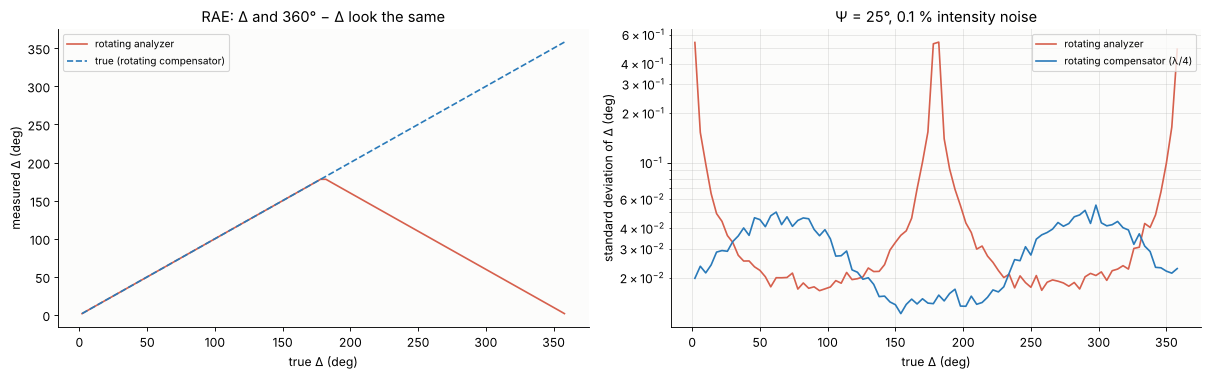

RAE at Delta = 178 deg: 0.49 deg; at 90 deg: 0.018 deg; RCE everywhere 0.012 to 0.055 deg


In [5]:
rng = np.random.default_rng(3)
deltas = np.linspace(2, 358, 90)
psi0 = 25.0
A = np.arange(0, 180, 5.0)
Cang = np.arange(0, 180, 5.0)
sd_rae, sd_rce, bias_rae = [], [], []
for dlt in deltas:
    N, C, S = el.ncs_from_psi_delta(psi0, dlt)
    sig_a = el.ellipsometer_signal(N, C, S, 45.0, A)
    sig_c = el.ellipsometer_signal(N, C, S, 45.0, 45.0, Cang)
    da, dc = [], []
    for _ in range(100):
        n_, c_, _s = el.fit_ncs(sig_a*(1 + 1e-3*rng.standard_normal(sig_a.shape)), 45.0, A)
        da.append(el.psi_delta_from_ncs(n_, c_)[1])
        dc.append(el.psi_delta_from_ncs(*el.fit_ncs(
            sig_c*(1 + 1e-3*rng.standard_normal(sig_c.shape)), 45.0, 45.0, Cang))[1])
    da, dc = np.array(da), np.array(dc)
    sd_rae.append(np.std(da))
    bias_rae.append(np.mean(da))
    sd_rce.append(np.std((dc - dlt + 180) % 360 - 180))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
axs[0].plot(deltas, bias_rae, color=RED, label="rotating analyzer")
axs[0].plot(deltas, deltas, color=BLUE, ls="--", label="true (rotating compensator)")
axs[0].set_xlabel("true Δ (deg)")
axs[0].set_ylabel("measured Δ (deg)")
axs[0].set_title("RAE: Δ and 360° − Δ look the same")
axs[0].legend(fontsize=9)
axs[1].semilogy(deltas, sd_rae, color=RED, label="rotating analyzer")
axs[1].semilogy(deltas, sd_rce, color=BLUE, label="rotating compensator (λ/4)")
axs[1].set_xlabel("true Δ (deg)")
axs[1].set_ylabel("standard deviation of Δ (deg)")
axs[1].set_title("Ψ = 25°, 0.1 % intensity noise")
axs[1].legend(fontsize=9)
axs[1].grid(alpha=0.3, which="both")
plt.show()
print("RAE at Delta = 178 deg: {:.2f} deg; at 90 deg: {:.3f} deg; RCE everywhere {:.3f} to {:.3f} deg"
      .format(sd_rae[-1], sd_rae[len(deltas)//4], min(sd_rce), max(sd_rce)))

The rotating analyzer folds $\Delta$ into [0°, 180°] and its noise grows
without bound towards 0° and 180°, where $\cos\Delta$ is flat. Classic
RAE instruments added a fixed compensator that could be switched in for
such samples; modern ones rotate the compensator (or use photoelastic
modulators) and measure $N$, $C$ and $S$ with uniform precision. A
rotating compensator also measures the **degree of polarization**
$\sqrt{N^2 + C^2 + S^2}$, which section 6 uses.

## 4. Dispersion models

Spectroscopic ellipsometry needs the optical constants of every layer at
every wavelength, described by a few parameters:

- **Cauchy**, $n = A + B/\lambda^2 + C/\lambda^4$, for transparent films
  (`el.cauchy()`); SiO₂ also by Malitson's Sellmeier formula
  (`el.sio2_index()`),
- **Tauc-Lorentz** (Jellison and Modine 1996) for amorphous
  semiconductors and dielectrics: a Lorentz oscillator times the Tauc
  density of states, zero absorption below the gap, $\varepsilon_1$ from
  Kramers-Kronig in closed form (`el.tauc_lorentz()`; the test suite
  checks it against the numerical integral),
- **Lorentz** and **Drude** oscillators (`el.lorentz()`, `el.drude()`)
  for absorption bands and free carriers,
- the **Bruggeman effective medium** (`el.bruggeman()`), which mixes two
  materials; a surface roughness layer is the film mixed 50:50 with
  void.

The crystalline silicon of the substrate is `el.silicon_index()`, an
interpolation of rounded values of Green (2008) between 400 and 1000 nm.

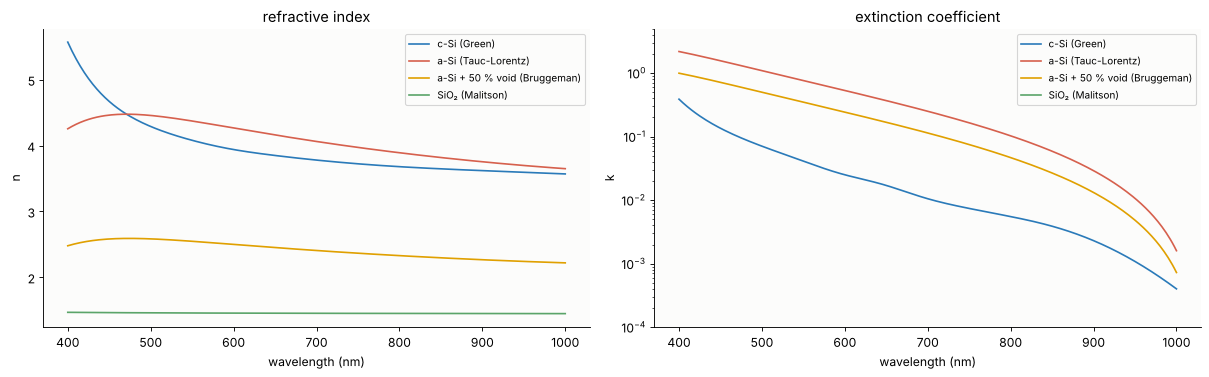

In [6]:
wl = np.linspace(0.4, 1.0, 241)
E = el.photon_energy(wl)
TL_ASI = dict(A=122.0, E0=3.45, C=2.54, Eg=1.20, eps_inf=1.15)     # a-Si, Jellison and Modine
n_asi = el.index_from_eps(el.tauc_lorentz(E, **TL_ASI))
n_rough = el.index_from_eps(el.bruggeman(n_asi**2, 1.0, 0.5))
n_si = el.silicon_index(wl)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
for N, c, name in ((n_si, BLUE, "c-Si (Green)"), (n_asi, RED, "a-Si (Tauc-Lorentz)"),
                   (n_rough, ORANGE, "a-Si + 50 % void (Bruggeman)"),
                   (el.sio2_index(wl), GREEN, "SiO₂ (Malitson)")):
    axs[0].plot(wl*1e3, N.real, color=c, label=name)
    axs[1].semilogy(wl*1e3, N.imag + 1e-6, color=c, label=name)
axs[0].set_ylabel("n")
axs[1].set_ylabel("k")
axs[1].set_ylim(1e-4, 5)
for ax in axs:
    ax.set_xlabel("wavelength (nm)")
    ax.legend(fontsize=9)
axs[0].set_title("refractive index")
axs[1].set_title("extinction coefficient")
plt.show()

## 5. Spectroscopic model fits

A fit adjusts the model parameters until the computed $\Psi$ and
$\Delta$ match the measured spectra, here by Levenberg-Marquardt
(`el.fit_psi_delta()`). Its quality is judged by Jellison's mean squared
error,

$$
\mathrm{MSE} = \frac{1}{2n - m}\sum_{j=1}^{n}\left[
  \left(\frac{\Psi_j^\mathrm{mod} - \Psi_j}{\sigma_{\Psi,j}}\right)^2
  + \left(\frac{\Delta_j^\mathrm{mod} - \Delta_j}{\sigma_{\Delta,j}}\right)^2\right],
$$

about 1 for a model that fits within the noise, and by the parameter
correlations from the Jacobian. The "measurements" below are computed
with noise of 0.02° in $\Psi$ and 0.04° in $\Delta$ at 65°, 70° and 75°
from 400 to 1000 nm.

### A thermal oxide

EllipsometryFit([1.448 +- 5.2e-05, 0.0035484 +- 1.1e-05, 0.1023 +- 1.8e-06], MSE = 1.46)
n(632.8 nm) = 1.4569 (Malitson 1.4570), thickness 102.302 +- 0.002 nm


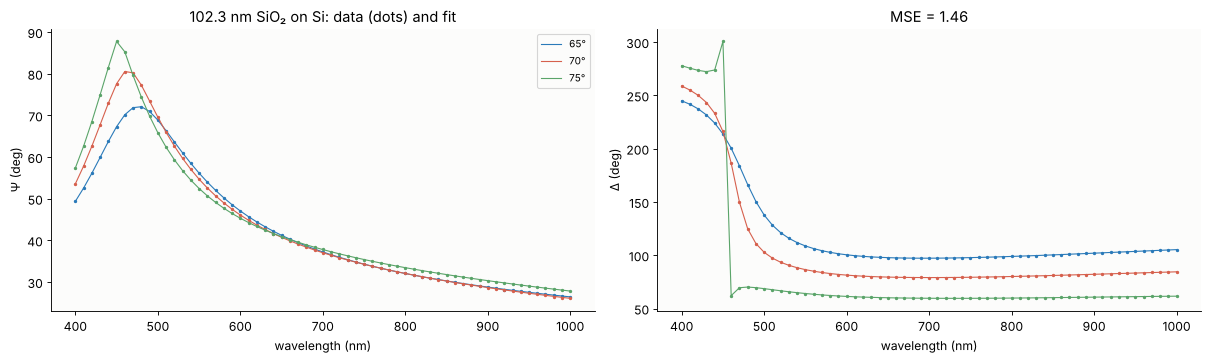

In [7]:
wl = np.linspace(0.4, 1.0, 61)
angles = np.array([65.0, 70.0, 75.0])
W, AN = np.meshgrid(wl, angles, indexing="ij")
SIG_P, SIG_D = 0.02, 0.04


def measure(model_layers, substrate=el.silicon_index):
    psi, delta = el.psi_delta(W, AN, model_layers, substrate)
    return (psi + SIG_P*rng.standard_normal(psi.shape),
            delta + SIG_D*rng.standard_normal(delta.shape))


psi_m, delta_m = measure([(el.sio2_index, 0.1023)])


def oxide(p):
    return el.psi_delta(W, AN, [(lambda w: el.cauchy(w, p[0], p[1]), p[2])], el.silicon_index)


fit = el.fit_psi_delta(oxide, (1.5, 0.0, 0.08), psi_m, delta_m, SIG_P, SIG_D)
print(fit)
print("n(632.8 nm) = {:.4f} (Malitson {:.4f}), thickness {:.3f} +- {:.3f} nm".format(
    el.cauchy(0.6328, *fit.params[:2]).real, el.sio2_index(0.6328).real, fit.params[2]*1e3,
    fit.std[2]*1e3))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained")
for j, (a, c) in enumerate(zip(angles, (BLUE, RED, GREEN))):
    axs[0].plot(wl*1e3, psi_m[:, j], ".", color=c, ms=4)
    axs[0].plot(wl*1e3, fit.psi[:, j], color=c, lw=1, label="{:.0f}°".format(a))
    axs[1].plot(wl*1e3, delta_m[:, j], ".", color=c, ms=4)
    axs[1].plot(wl*1e3, fit.delta[:, j], color=c, lw=1)
axs[0].set_ylabel("Ψ (deg)")
axs[1].set_ylabel("Δ (deg)")
for ax in axs:
    ax.set_xlabel("wavelength (nm)")
axs[0].legend(fontsize=9)
axs[0].set_title("102.3 nm SiO₂ on Si: data (dots) and fit")
axs[1].set_title("MSE = {:.2f}".format(fit.mse))
plt.show()

Thickness and Cauchy coefficients come out right, with a statistical
uncertainty of a few thousandths of a nanometre in the thickness and the
index good to the fourth decimal. The MSE of about 1.5 is slightly above
1 because the two-term Cauchy formula does not quite follow Malitson's
dispersion of the "sample" over 400 to 1000 nm (a third term brings it
to 1). Such statistical errors are far below the real accuracy, which is
limited by systematic errors: the calibration of the angle of incidence
and of the optics, and the model itself, as the next example shows.

### Very thin films: thickness against index

For films much thinner than the wavelength, $\Delta$ depends to first
order on the product of thickness and optical contrast only (Drude's
approximation), so the fit can hardly tell a thin dense film from a
thicker light one: the correlation coefficient between $n$ and $d$
approaches −1. With random noise alone the fit still separates them, but
real data also carry systematic errors. Below fits of a constant index
$n$ and the thickness $d$ of SiO₂ films ($n = 1.46$) from 2 to 200 nm
with the angle of incidence miscalibrated by 0.05°, once with $n$ free
and once with $n$ fixed to the right value.

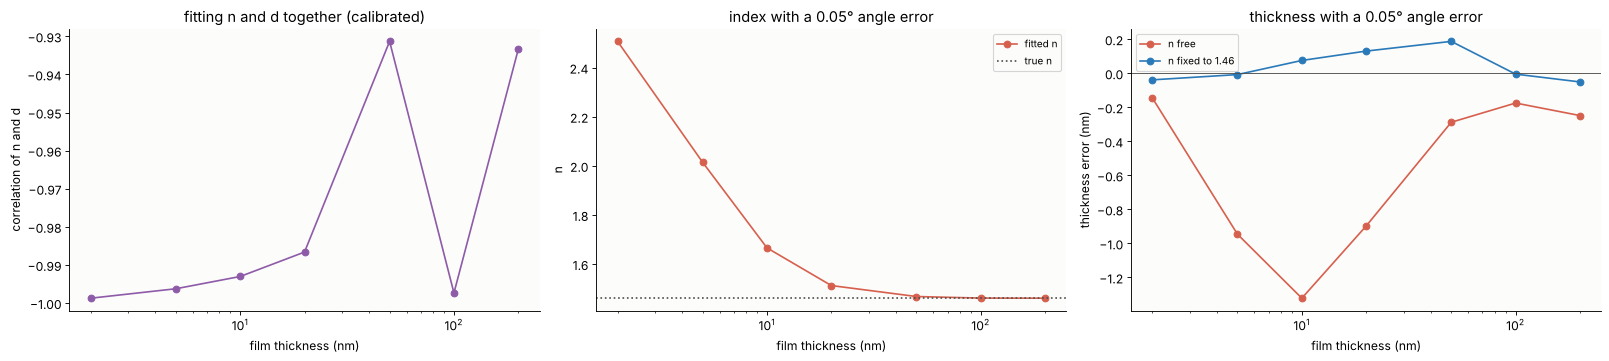

d =   2.0 nm: correlation -0.9987; n free: n = 2.507, error of d -0.15 nm, MSE   741; n fixed: error of d -0.039 nm
d =   5.0 nm: correlation -0.9962; n free: n = 2.015, error of d -0.95 nm, MSE   173; n fixed: error of d -0.008 nm
d =  10.0 nm: correlation -0.9930; n free: n = 1.666, error of d -1.32 nm, MSE    61; n fixed: error of d +0.075 nm
d =  20.0 nm: correlation -0.9866; n free: n = 1.512, error of d -0.90 nm, MSE    21; n fixed: error of d +0.130 nm
d =  50.0 nm: correlation -0.9313; n free: n = 1.468, error of d -0.29 nm, MSE     6; n fixed: error of d +0.187 nm
d = 100.0 nm: correlation -0.9973; n free: n = 1.461, error of d -0.17 nm, MSE     6; n fixed: error of d -0.005 nm
d = 200.0 nm: correlation -0.9334; n free: n = 1.461, error of d -0.25 nm, MSE    10; n fixed: error of d -0.051 nm


In [8]:
thick = np.array([0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2])
corr, n_free, d_free, d_fixed, mse_free = [], [], [], [], []
for t in thick:
    psi_t, delta_t = el.psi_delta(W, AN + 0.05, [(1.46, t)], el.silicon_index)   # angle off by 0.05 deg
    psi_t = psi_t + SIG_P*rng.standard_normal(psi_t.shape)
    delta_t = delta_t + SIG_D*rng.standard_normal(delta_t.shape)
    f = el.fit_psi_delta(lambda p: el.psi_delta(W, AN, [(p[0], p[1])], el.silicon_index),
                         (1.46, t), psi_t, delta_t, SIG_P, SIG_D)
    g = el.fit_psi_delta(lambda p: el.psi_delta(W, AN, [(1.46, p[0])], el.silicon_index),
                         (t,), psi_t, delta_t, SIG_P, SIG_D)
    psi_0, delta_0 = el.psi_delta(W, AN, [(1.46, t)], el.silicon_index)       # calibrated
    f0 = el.fit_psi_delta(lambda p: el.psi_delta(W, AN, [(p[0], p[1])], el.silicon_index),
                          (1.46, t), psi_0, delta_0, SIG_P, SIG_D)
    corr.append(f0.correlation[0, 1])
    n_free.append(f.params[0])
    d_free.append(f.params[1] - t)
    d_fixed.append(g.params[0] - t)
    mse_free.append(f.mse)
fig, axs = plt.subplots(1, 3, figsize=(20, 4.4), layout="constrained")
axs[0].semilogx(thick*1e3, corr, "o-", color=PURPLE)
axs[0].set_xlabel("film thickness (nm)")
axs[0].set_ylabel("correlation of n and d")
axs[0].set_title("fitting n and d together (calibrated)")
axs[1].semilogx(thick*1e3, n_free, "o-", color=RED, label="fitted n")
axs[1].axhline(1.46, color="0.3", ls=":", label="true n")
axs[1].set_xlabel("film thickness (nm)")
axs[1].set_ylabel("n")
axs[1].set_title("index with a 0.05° angle error")
axs[1].legend(fontsize=9)
axs[2].semilogx(thick*1e3, np.array(d_free)*1e3, "o-", color=RED, label="n free")
axs[2].semilogx(thick*1e3, np.array(d_fixed)*1e3, "o-", color=BLUE, label="n fixed to 1.46")
axs[2].axhline(0, color="0.3", lw=0.8)
axs[2].set_xlabel("film thickness (nm)")
axs[2].set_ylabel("thickness error (nm)")
axs[2].set_title("thickness with a 0.05° angle error")
axs[2].legend(fontsize=9)
plt.show()
for t, c, n, a, b, m in zip(thick, corr, n_free, d_free, d_fixed, mse_free):
    print("d = {:5.1f} nm: correlation {:+.4f}; n free: n = {:.3f}, error of d {:+.2f} nm, MSE {:5.0f}; "
          "n fixed: error of d {:+.3f} nm".format(t*1e3, c, n, a*1e3, m, b*1e3))

A twentieth of a degree is enough: the free fit of a 2 nm oxide returns
an index of 2.5 instead of 1.46, of a 10 nm oxide still 1.67, with
thickness errors of up to a nanometre and more. With the index fixed the
thickness is right to about a tenth of a nanometre. The correlation of
the calibrated fits is close to −1 at all thicknesses (index and
thickness enter mainly as the optical thickness $nd$), but only above
about 50 nm does the dispersion of the interference fringes over the
spectrum pin the index down, and the free fit becomes robust. Native oxides and other films
below 10 nm are therefore always fitted with fixed optical constants,
and the angle of incidence is calibrated on a reference wafer, often
together with the thickness of its oxide. The large MSE flags the
systematic error here; in a real measurement the culprit has to be
found.

### Amorphous silicon with surface roughness

A 60 nm film of amorphous silicon on thermal oxide on silicon, with a
3 nm rough surface, modelled as a Bruggeman mixture of a-Si and void.
The fit has seven parameters: the five Tauc-Lorentz parameters, the
thickness and the roughness, the oxide below is known. A model without
the roughness layer gets a clearly worse MSE, the usual way of deciding
whether a layer belongs into a model.

fits: 2.4 s
                     true     with roughness      without
A (eV)            122.000   122.047 +-  0.130      102.970
E0 (eV)             3.450     3.450 +-  0.001        3.272
C (eV)              2.540     2.541 +-  0.002        2.593
Eg (eV)             1.200     1.200 +-  0.000        1.197
eps_inf             1.150     1.151 +-  0.009        3.000
d (nm)             60.000    60.001 +-  0.005       63.160
roughness (nm)      3.000     2.997 +-  0.003        0.000
MSE with roughness 0.97, without 3517.3


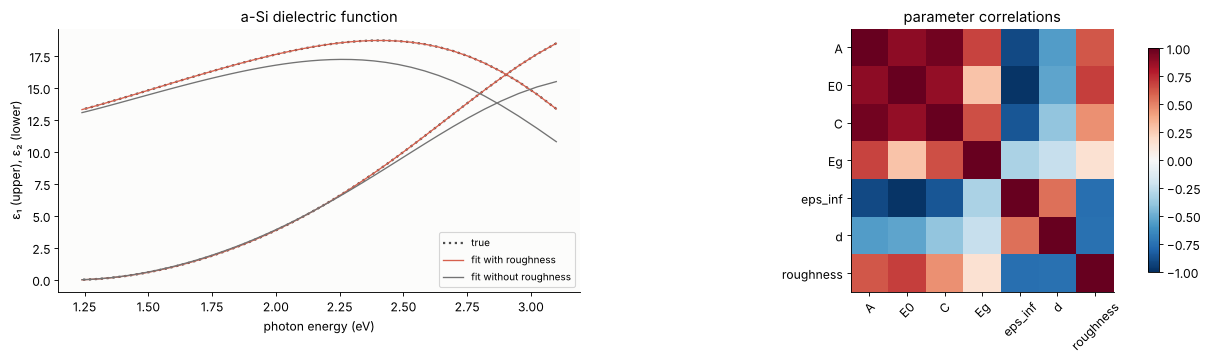

In [9]:
def asi_stack(p, roughness=True):
    A, E0, C, Eg, einf, d, r = p

    def n_a(w):
        return el.index_from_eps(el.tauc_lorentz(el.photon_energy(w), A, E0, C, Eg, einf))

    def n_r(w):
        return el.index_from_eps(el.bruggeman(n_a(w)**2, 1.0, 0.5))

    layers = ([(n_r, r)] if roughness else []) + [(n_a, d), (el.sio2_index, 0.100)]
    return layers


true = (TL_ASI["A"], TL_ASI["E0"], TL_ASI["C"], TL_ASI["Eg"], TL_ASI["eps_inf"], 0.060, 0.003)
psi_a, delta_a = measure(asi_stack(true))
start = (110.0, 3.6, 2.3, 1.3, 1.0, 0.055, 0.001)
lb = (20.0, 2.0, 0.5, 0.5, 0.5, 0.03, 0.0)
ub = (300.0, 5.0, 4.0, 1.8, 3.0, 0.09, 0.02)
t0 = time.time()
fit_r = el.fit_psi_delta(lambda p: el.psi_delta(W, AN, asi_stack(p), el.silicon_index), start,
                         psi_a, delta_a, SIG_P, SIG_D, bounds=(lb, ub))
fit_0 = el.fit_psi_delta(lambda p: el.psi_delta(W, AN, asi_stack(list(p) + [0.0], False),
                                                el.silicon_index),
                         start[:6], psi_a, delta_a, SIG_P, SIG_D, bounds=(lb[:6], ub[:6]))
print("fits: {:.1f} s".format(time.time() - t0))
names = ("A (eV)", "E0 (eV)", "C (eV)", "Eg (eV)", "eps_inf", "d (nm)", "roughness (nm)")
scale = (1, 1, 1, 1, 1, 1e3, 1e3)
print("{:15s} {:>9s} {:>18s} {:>12s}".format("", "true", "with roughness", "without"))
for i, (nm, sc) in enumerate(zip(names, scale)):
    wo = fit_0.params[i]*sc if i < 6 else 0.0
    print("{:15s} {:9.3f} {:9.3f} +- {:6.3f} {:12.3f}".format(nm, true[i]*sc, fit_r.params[i]*sc,
                                                            fit_r.std[i]*sc, wo))
print("MSE with roughness {:.2f}, without {:.1f}".format(fit_r.mse, fit_0.mse))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained")
E_plot = el.photon_energy(wl)
for p, c, lab in ((true, "0.3", "true"), (fit_r.params, RED, "fit with roughness"),
                  (list(fit_0.params) + [0.0], GREY, "fit without roughness")):
    e = el.tauc_lorentz(E_plot, *p[:5])
    axs[0].plot(E_plot, e.imag, color=c, ls="-" if c != "0.3" else ":", lw=2 if c == "0.3" else 1.2,
                label=lab)
    axs[0].plot(E_plot, e.real, color=c, ls="-" if c != "0.3" else ":", lw=2 if c == "0.3" else 1.2)
axs[0].set_xlabel("photon energy (eV)")
axs[0].set_ylabel("ε₁ (upper), ε₂ (lower)")
axs[0].set_title("a-Si dielectric function")
axs[0].legend(fontsize=9)
im = axs[1].imshow(fit_r.correlation, cmap="RdBu_r", vmin=-1, vmax=1)
axs[1].set_xticks(range(7), [n.split(" ")[0] for n in names], rotation=45)
axs[1].set_yticks(range(7), [n.split(" ")[0] for n in names])
axs[1].set_title("parameter correlations")
plt.colorbar(im, ax=axs[1], shrink=0.85)
plt.show()

With the roughness layer the fit recovers thickness and roughness to a
fraction of a nanometre and the dielectric function of the film; the
model without it reaches a much higher MSE and compensates with a wrong
thickness and wrong oscillator parameters. The correlation matrix shows
the Tauc-Lorentz parameters strongly coupled to each other: different
parameter sets give nearly the same $\varepsilon(E)$ over the measured
range, so the dielectric function is far better determined than the
individual parameters. This is typical: report the optical constants,
not the oscillator parameters.

## 6. Depolarization

An ellipsometer averages over its spot, its angles and its bandwidth.
When $\rho$ varies over them, the reflected light is partly
unpolarized: the measurement is an incoherent sum of Mueller matrices,
with a **degree of polarization** below 1. A thick film is the classic
case: the phase across the film changes quickly with the wavelength, and
a spectrometer with a 2 nm bandpass averages over fringes. A rotating
compensator measures the depolarization; a model that ignores it fits
badly near the fringes.

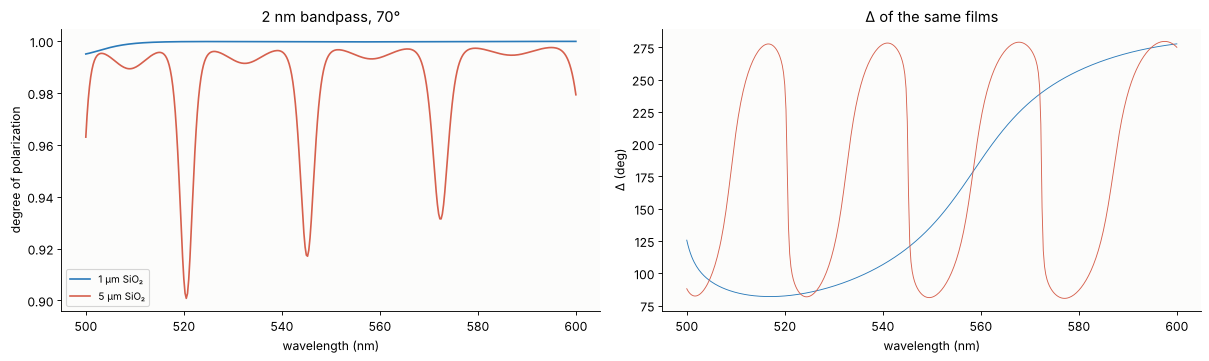

In [10]:
wl_d = np.linspace(0.5, 0.6, 401)
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), layout="constrained")
for t_film, c in ((1.0, BLUE), (5.0, RED)):
    P_list = []
    for w in wl_d:
        sub = np.linspace(w - 0.001, w + 0.001, 21)          # 2 nm bandpass
        N, C, S = el.ncs_from_psi_delta(*el.psi_delta(sub, 70.0, [(el.sio2_index, t_film)],
                                                      el.silicon_index))
        sig = el.ellipsometer_signal(N.mean(), C.mean(), S.mean(), 45.0, 45.0, Cang)
        P_list.append(el.psi_delta_from_ncs(*el.fit_ncs(sig, 45.0, 45.0, Cang))[2])
    axs[0].plot(wl_d*1e3, P_list, color=c, label="{:.0f} µm SiO₂".format(t_film))
    psi, delta = el.psi_delta(wl_d, 70.0, [(el.sio2_index, t_film)], el.silicon_index)
    axs[1].plot(wl_d*1e3, delta, color=c, lw=0.8)
axs[0].set_xlabel("wavelength (nm)")
axs[0].set_ylabel("degree of polarization")
axs[0].set_title("2 nm bandpass, 70°")
axs[0].legend(fontsize=9)
axs[1].set_xlabel("wavelength (nm)")
axs[1].set_ylabel("Δ (deg)")
axs[1].set_title("Δ of the same films")
plt.show()

A 1 µm oxide stays almost fully polarized, a 5 µm oxide depolarizes by
up to 10 % wherever $\Delta$ swings fastest. Fitting software
convolves the model with the bandpass of the instrument (and with the
spread of angles and thicknesses) for such samples; ignoring it biases
the thickness of thick films and the optical constants near sharp
features.

## Summary

- Ellipsometry measures $\rho = r_p/r_s = \tan\Psi e^{i\Delta}$, a ratio
  that is immune to intensity drifts; $\Delta$ moves by about 3° per
  nanometre of native oxide on silicon.
- $\Psi$ and $\Delta$ are periodic in the thickness of a transparent
  film; several wavelengths and angles remove the ambiguity.
- A rotating analyzer measures only $\cos\Delta$ and fails near 0° and
  180°; a rotating compensator measures $N$, $C$, $S$ and the degree of
  polarization with uniform precision.
- Results come from model fits: Cauchy for transparent films,
  Tauc-Lorentz for amorphous materials, Bruggeman for roughness. The MSE
  decides whether a model is adequate, the correlation matrix which
  parameters are determined: thickness and index of films below 10 nm
  are not separable in practice, a small calibration error throws the
  index off completely.
- Thick films and finite bandwidths depolarize; the models must
  average over the instrument's bandpass.

## References

- H. Fujiwara, *Spectroscopic Ellipsometry: Principles and
  Applications*, Wiley (2007).
- R. M. A. Azzam and N. M. Bashara, *Ellipsometry and Polarized Light*,
  North-Holland (1977).
- H. G. Tompkins and E. A. Irene (eds.), *Handbook of Ellipsometry*,
  William Andrew (2005).
- R. H. Muller, "Definitions and conventions in ellipsometry", Surf.
  Sci. 16, 14 (1969).
- G. E. Jellison and F. A. Modine, "Parameterization of the optical
  functions of amorphous materials in the interband region", Appl. Phys.
  Lett. 69, 371 (1996).
- G. E. Jellison, "Data analysis for spectroscopic ellipsometry", Thin
  Solid Films 234, 416 (1993).
- D. E. Aspnes and A. A. Studna, "Dielectric functions and optical
  parameters of Si, Ge, GaP, GaAs, GaSb, InP, InAs, and InSb from 1.5 to
  6.0 eV", Phys. Rev. B 27, 985 (1983).
- M. A. Green, "Self-consistent optical parameters of intrinsic silicon
  at 300 K including temperature coefficients", Sol. Energy Mater. Sol.
  Cells 92, 1305 (2008).

In [11]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 23 s
